# RSA External Practical
## Set B

By *23AIML049, Hari Patel*

In [24]:
!pip install lime

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283913 sha256=11af285775c89a76e42e37ec89598d96b3d51e84836bd303276c2c5adc882fc9
  Stored in directory: /root/.cache/pip/wheels/7c/04/5c/157dc9106512a6c7a30653ec064490c94a49e0fc8f63d19ab9
Successfully built lime


In [30]:
# Libraries
import numpy as np
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score
import shap
from lime.lime_tabular import LimeTabularExplainer
import matplotlib.pyplot as plt

## Task 1 :Load german_credit.csv, encode the categorical attributes, and split the data 80:20 (stratified, random_state = 42).

In [51]:
# Load the dataset
data = fetch_openml("credit-g", version=1, as_frame=True)
X, y = data.data.copy(), data.target
y = LabelEncoder().fit_transform(y)

# Ordinal Encoder for X(2D)
X = OrdinalEncoder().fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

## Task 2: Training Random Forest Model

In [52]:
model = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42)
model.fit(X_train, y_train)

acc = accuracy_score(y_test, model.predict(X_test))
# Test Accuracy
print(f"Random Forest test accuracy: {acc*100:.2f}%\n")

# ROC AUC
y_pred_proba = model.predict_proba(X_test)
roc_auc = roc_auc_score(y_test, y_pred_proba[:, 1])
print(f"Random Forest ROC AUC: {roc_auc*100:.2f}%\n")

Random Forest test accuracy: 73.50%

Random Forest ROC AUC: 78.49%



## Task 3: Use SHAP (TreeExplainer) to compute global feature importance; draw the SHAP summary (beeswarm or bar) plot and list the top 5 features.

Top-5 global features (mean |SHAP value|):
  checking_status     : 0.0894
  purpose             : 0.0438
  credit_amount       : 0.0326
  duration            : 0.0313
  age                 : 0.0293


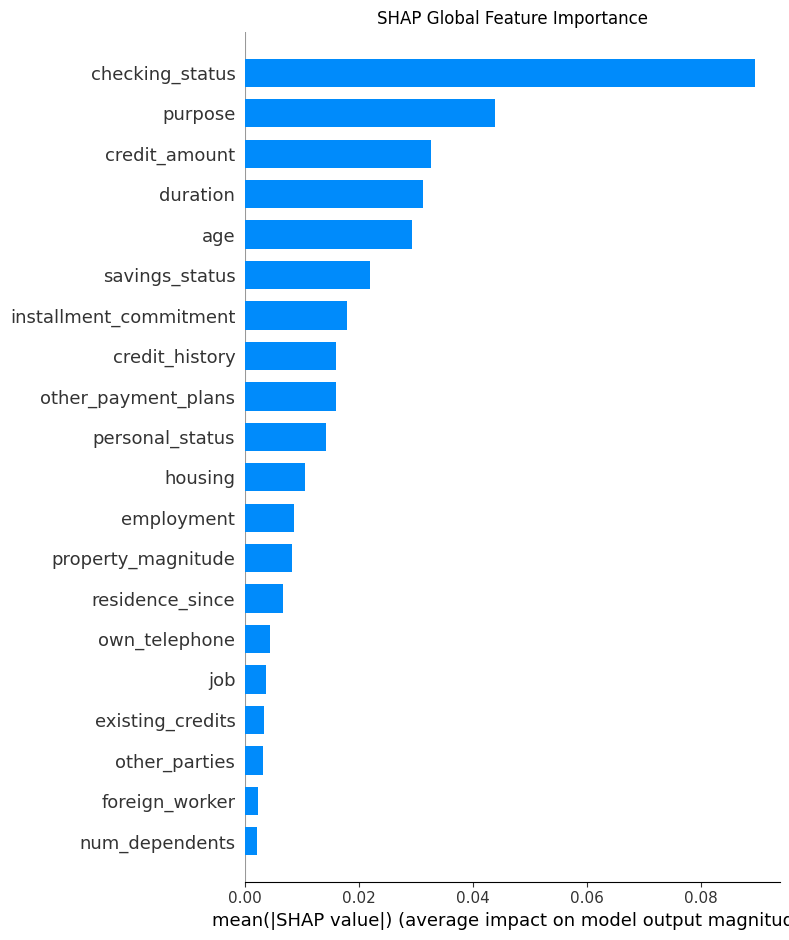

In [55]:
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

if isinstance(shap_values, list):
    shap_class1 = shap_values[1]
elif np.asarray(shap_values).ndim == 3:
    shap_class1 = np.asarray(shap_values)[:, :, 1]
else:
    shap_class1 = np.asarray(shap_values)

expected_value = explainer.expected_value
if isinstance(expected_value, (list, np.ndarray)) and np.asarray(expected_value).size > 1:
    expected_value = np.asarray(expected_value)[1]

global_importance = np.abs(shap_class1).mean(axis=0)
# Use the original DataFrame columns from the fetched data
feature_names = data.data.columns
top_shap = sorted(
    zip(feature_names, global_importance),
    key=lambda x: -x[1]
)[:5]

print("Top-5 global features (mean |SHAP value|):")
for feat, val in top_shap:
    print(f"  {feat:20s}: {val:.4f}")

shap.summary_plot(
    shap_class1, X_test, feature_names=feature_names, plot_type="bar", show=False
)
plt.title(f"SHAP Global Feature Importance")
plt.tight_layout()
plt.savefig("shap_global_importance.png")
plt.show()

## Task 4: Select one applicant from the test set who is predicted "bad" (rejected) and draw a SHAP waterfall/force plot; list the top 3 reasons.


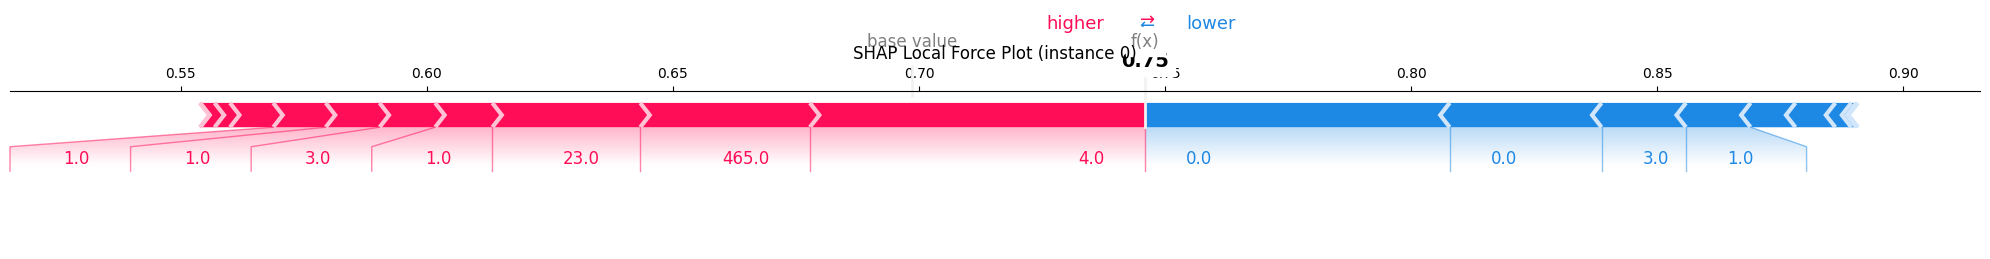

Top 3 local reasons for this output:
1. savings_status: +0.0682 (positive (favors approval))
2. checking_status: -0.0618 (negative (favors rejection))
3. credit_amount: +0.0345 (positive (favors approval))


In [65]:
instance_idx = 0

shap.force_plot(
    expected_value,
    shap_class1[instance_idx],
    X_test[instance_idx],
    matplotlib=True,
    show=False
)
plt.title(f"SHAP Local Force Plot (instance {instance_idx})")
plt.tight_layout()
plt.savefig("shap_local_force.png")
plt.show()

# Sort features by absolute contribution magnitude for this instance
local_reasons = sorted(
    zip(feature_names, shap_class1[instance_idx]),
    key=lambda x: -abs(x[1])
)[:3]

print("Top 3 local reasons for this output:")
for idx, (feat, val) in enumerate(local_reasons, 1):
    direction = "positive (favors approval)" if val > 0 else "negative (favors rejection)"
    print(f"{idx}. {feat}: {val:+.4f} ({direction})")

The top 3 reasons are:
1.
2.
3.

## Task 5: Explain the same applicant with LIME (num_features = 5) and compare the LIME and SHAP reasons (agreement of the top 3).

In [61]:
feature_names = data.data.columns.tolist()

lime_explainer = LimeTabularExplainer(
    X_train,
    feature_names=feature_names,
    class_names=["bad", "good"],
    discretize_continuous=True
)

lime_exp = lime_explainer.explain_instance(
    X_test[instance_idx],
    model.predict_proba,
    num_features=5
)

print(f"\nLIME top-5 features for instance {instance_idx}:")
for feat, weight in lime_exp.as_list():
    print(f"  {feat:30s}: {weight:+.4f}")

shap_top_for_instance = sorted(
    zip(feature_names, shap_class1[instance_idx]),
    key=lambda x: -abs(x[1])
)[:5]

print(f"\nSHAP top-5 features for instance {instance_idx}:")
for feat, val in shap_top_for_instance:
    print(f"  {feat:30s}: {val:+.4f}")

def top_feature_shap(i):
    return feature_names[np.argmax(np.abs(shap_class1[i]))]

def extract_feature_name(lime_rule, columns):
    for col in columns:
        if col in lime_rule:
            return col
    return lime_rule

def top_feature_lime(i):
    exp = lime_explainer.explain_instance(
        X_test[i],
        model.predict_proba,
        num_features=1
    )
    rule = exp.as_list()[0][0]
    return extract_feature_name(rule, feature_names)

agreements = []

for i in range(min(15, len(X_test))):
    s_feat = top_feature_shap(i)
    l_feat = top_feature_lime(i)
    if s_feat == l_feat:
        agreements.append(
            (i, s_feat, l_feat, s_feat == l_feat)
        )

print(
    f"\nInstances where LIME and SHAP top feature agree: "
    f"{len(agreements)}/{min(15, len(X_test))}"
)

for i, s_feat, l_feat, _ in agreements[:3]:
    print(
        f"  Instance {i}: "
        f"SHAP top='{s_feat}' vs LIME top='{l_feat}'"
    )



LIME top-5 features for instance 0:
  checking_status <= 0.00       : -0.0876
  purpose <= 3.00               : -0.0614
  savings_status > 2.00         : +0.0497
  age > 22.00                   : +0.0470
  423.50 < credit_amount <= 663.50: +0.0431

SHAP top-5 features for instance 0:
  savings_status                : +0.0682
  checking_status               : -0.0618
  credit_amount                 : +0.0345
  purpose                       : -0.0309
  age                           : +0.0301

Instances where LIME and SHAP top feature agree: 8/15
  Instance 3: SHAP top='checking_status' vs LIME top='checking_status'
  Instance 6: SHAP top='checking_status' vs LIME top='checking_status'
  Instance 7: SHAP top='checking_status' vs LIME top='checking_status'


## Task 6: Write a plain-language rejection message for this applicant using the top reasons, and check whether any sensitive attribute (age, personal_status, foreign_worker) appears among the reasons

In [64]:
top_negative_reasons = [
    "Checking account status (lower or negative balance)",
    "Purpose of the credit application"
]

sensitive_attributes = ["age", "personal_status", "foreign_worker"]

shap_features_instance_0 = [feat for feat, val in shap_top_for_instance]

sensitive_detected = [attr for attr in sensitive_attributes if attr in shap_features_instance_0]

rejection_message = f"""
Your EMI request was not
approved mainly because of the following reasons:
1. Your checking account status (e.g., low or no existing checking balance).
2. The specified purpose of your loan application.

"""

print("Plain-Language Rejection Message")
print(rejection_message)
print("Sensitive Attribute Check")
print(f"Sensitive attributes monitored: {sensitive_attributes}")
print(f"Top SHAP features for this applicant: {shap_features_instance_0}")
if sensitive_detected:
    print(f"WARNING: Sensitive attribute(s) {sensitive_detected} detected among the top feature reasons.")
else:
    print("SUCCESS: No sensitive attributes found among the top features influencing the decision.")

Plain-Language Rejection Message

Your EMI request was not
approved mainly because of the following reasons:
1. Your checking account status (e.g., low or no existing checking balance).
2. The specified purpose of your loan application.


Sensitive Attribute Check
Sensitive attributes monitored: ['age', 'personal_status', 'foreign_worker']
Top SHAP features for this applicant: ['savings_status', 'checking_status', 'credit_amount', 'purpose', 'age']
